Kelompok 3 (Qintara, Rey, Mikky = 1, 2, 8) = Data Kesehatan Mahasiswa
---


Import Dataset


In [ ]:
import pandas as pd

# Membaca dataset
df = pd.read_csv('indonesia_kesehatan_mental_gen_z_akademik_enriched_2026.csv')

# Menampilkan 5 baris pertama data
print(df.head())

# Melihat informasi kolom dan tipe data
print(df.info())

          responden_id jenjang_dan_rumpun_studi   status_perguruan_tinggi  \
0  GENZ_MHS_2026_00001    Ilmu Sosial & Politik  PTN Badan Hukum (PTN-BH)   
1  GENZ_MHS_2026_00002   Kedokteran & Kesehatan  PTN Badan Hukum (PTN-BH)   
2  GENZ_MHS_2026_00003   Kedokteran & Kesehatan  PTN Badan Hukum (PTN-BH)   
3  GENZ_MHS_2026_00004       Ilmu Komputer & IT          PTN BLU / Satker   
4  GENZ_MHS_2026_00005       Ilmu Komputer & IT     PTS Akreditasi Unggul   

  provinsi_domisili_kampus  semester_studi                       golongan_ukt  \
0        Kalimantan Tengah               5    UKT Golongan 3-4 (Rp 2jt - 4jt)   
1              DKI Jakarta               8        UKT Golongan 7-8 (> Rp 9jt)   
2         Sulawesi Selatan               4  UKT Golongan 1-2 (Rp 500rb - 1jt)   
3      Nusa Tenggara Timur               5    UKT Golongan 3-4 (Rp 2jt - 4jt)   
4               Jawa Timur               5    UKT Golongan 3-4 (Rp 2jt - 4jt)   

   indeks_prestasi_kumulatif_ipk  beban_sks_semest

Tahap EDA

In [ ]:
# 1. Informasi umum struktur data, jumlah baris/kolom, dan tipe data
print("--- INFO DATA ---")
df.info()

# 2. Cek missing values (data kosong)
print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

# 3. Statistik deskriptif untuk kolom numerik
print("\n--- STATISTIK DESKRIPTIF ---")
print(df[['indeks_prestasi_kumulatif_ipk', 'durasi_tidur_harian_jam', 'durasi_layar_harian_jam']].describe())

# 4. Distribusi dari kolom target (kategori keparahan depresi/kecemasan)
print("\n--- DISTRIBUSI KELAS TARGET ---")
print(df['kategori_keparahan_depresi_kecemasan'].value_counts())

--- INFO DATA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 29 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   responden_id                          2010 non-null   object 
 1   jenjang_dan_rumpun_studi              2010 non-null   object 
 2   status_perguruan_tinggi               2010 non-null   object 
 3   provinsi_domisili_kampus              2010 non-null   object 
 4   semester_studi                        2010 non-null   int64  
 5   golongan_ukt                          2010 non-null   object 
 6   indeks_prestasi_kumulatif_ipk         2010 non-null   float64
 7   beban_sks_semester_ini                2010 non-null   int64  
 8   durasi_layar_harian_jam               2010 non-null   float64
 9   durasi_tidur_harian_jam               2010 non-null   float64
 10  kondisi_tempat_tinggal                2010 non-null   object 
 11 

Klasifikasi Naive Bayes & Logistic Regression

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Menentukan Fitur (X) dan Target (y)
features = [
    'semester_studi', 'indeks_prestasi_kumulatif_ipk', 'beban_sks_semester_ini',
    'durasi_layar_harian_jam', 'durasi_tidur_harian_jam', 'skor_tekanan_finansial',
    'skor_kecemasan_akademik', 'skor_tekanan_masa_depan_karir', 'skor_kesepian_dan_isolasi_sosial'
]

# Menghapus baris yang mengandung missing value (NaN) pada fitur atau target
clean_df = df.dropna(subset=features + ['kategori_keparahan_depresi_kecemasan'])

X = clean_df[features]
y = clean_df['kategori_keparahan_depresi_kecemasan']

# 2. Split data: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Normalisasi fitur (StandardScaler) agar skala angka seragam
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- MODEL 1: NAIVE BAYES ---
print("="*40)
print("HASIL EVALUASI: NAIVE BAYES")
print("="*40)
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)

print("Akurasi Naive Bayes:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report Naive Bayes:")
print(classification_report(y_test, y_pred_nb))


# --- MODEL 2: LOGISTIC REGRESSION ---
print("="*40)
print("HASIL EVALUASI: LOGISTIC REGRESSION")
print("="*40)
# max_iter diperbesar agar model konvergen sempurna
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("Akurasi Logistic Regression:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report Logistic Regression:")
print(classification_report(y_test, y_pred_lr))

HASIL EVALUASI: NAIVE BAYES
Akurasi Naive Bayes: 0.7139303482587065

Classification Report Naive Bayes:
                precision    recall  f1-score   support

Berat / Kritis       0.74      0.63      0.68        54
       Minimal       0.62      0.29      0.39        28
        Ringan       0.55      0.65      0.60        94
        Sedang       0.79      0.81      0.80       226

      accuracy                           0.71       402
     macro avg       0.67      0.59      0.62       402
  weighted avg       0.72      0.71      0.71       402

HASIL EVALUASI: LOGISTIC REGRESSION
Akurasi Logistic Regression: 0.763681592039801

Classification Report Logistic Regression:
                precision    recall  f1-score   support

Berat / Kritis       0.77      0.76      0.77        54
       Minimal       0.64      0.32      0.43        28
        Ringan       0.64      0.67      0.65        94
        Sedang       0.82      0.86      0.84       226

      accuracy                      

Validasi (Evaluasi Model)

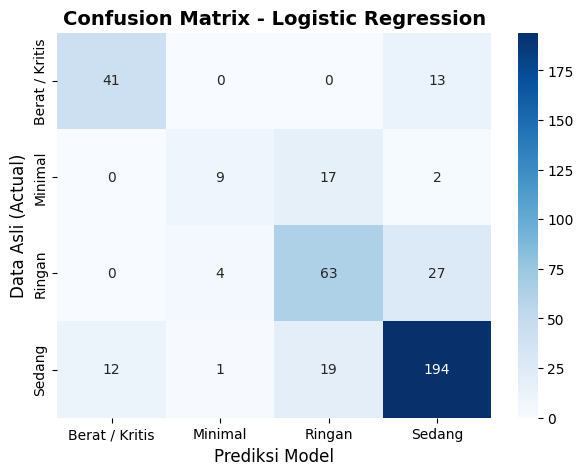

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Memilih model yang ingin dievaluasi (bisa 'y_pred_lr' atau 'y_pred_nb')
y_pred_aktif = y_pred_lr
nama_model = "Logistic Regression"

# Menghitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred_aktif)

# Visualisasi Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=lr_model.classes_,
            yticklabels=lr_model.classes_)
plt.title(f'Confusion Matrix - {nama_model}', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Data Asli (Actual)', fontsize=12)
plt.show()

Kurva ROC

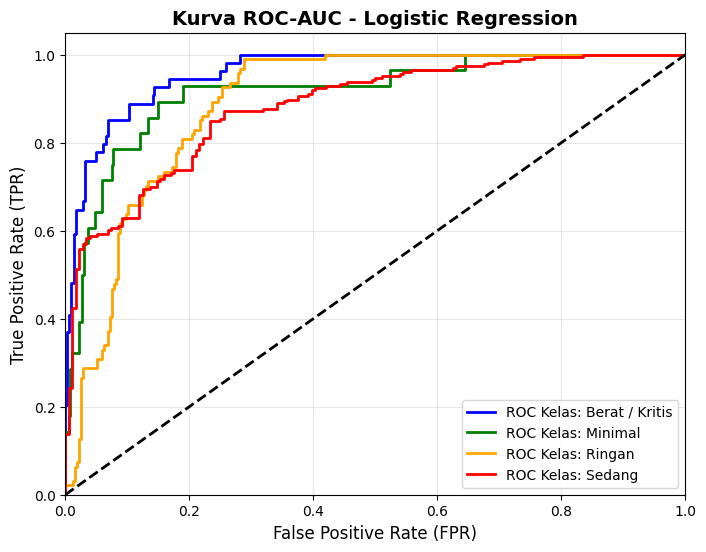

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

# Menyiapkan data biner untuk kurva ROC (One-vs-Rest)
classes = lr_model.classes_
y_test_biner = label_binarize(y_test, classes=classes)
y_prob = lr_model.predict_proba(X_test_scaled)

# Visualisasi Kurva ROC-AUC
plt.figure(figsize=(8, 6))
for i, color in zip(range(len(classes)), ['blue', 'green', 'orange', 'red', 'purple']):
    if i < y_test_biner.shape[1]:
        fpr, tpr, _ = roc_curve(y_test_biner[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, color=color, lw=2,
                 label=f'ROC Kelas: {classes[i]}')

plt.plot([0, 1], [0, 1], 'k--', lw=2) # Garis diagonal acak
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title(f'Kurva ROC-AUC - {nama_model}', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Feature Importance dari Logistic Regression

In [ ]:
import pandas as pd
# Melihat koefisien fitur pada Logistic Regression
importance = pd.DataFrame({
    'Fitur': features,
    'Koefisien': lr_model.coef_[0]
}).sort_values(by='Koefisien', ascending=False)
print(importance)

                              Fitur  Koefisien
6           skor_kecemasan_akademik   2.464103
5            skor_tekanan_finansial   1.906360
8  skor_kesepian_dan_isolasi_sosial   1.853605
7     skor_tekanan_masa_depan_karir   1.742849
2            beban_sks_semester_ini   0.715349
3           durasi_layar_harian_jam   0.103232
1     indeks_prestasi_kumulatif_ipk   0.010896
0                    semester_studi  -0.052069
4           durasi_tidur_harian_jam  -1.134017


Kode Uji VIF (Variance Inflation Factor)

In [ ]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = [
    'semester_studi', 'indeks_prestasi_kumulatif_ipk', 'beban_sks_semester_ini',
    'durasi_layar_harian_jam', 'durasi_tidur_harian_jam', 'skor_tekanan_finansial',
    'skor_kecemasan_akademik', 'skor_tekanan_masa_depan_karir', 'skor_kesepian_dan_isolasi_sosial'
]

# Membersihkan missing value (NaN) dari kolom fitur sebelum perhitungan VIF
clean_features_df = df[features].dropna()

# Menambahkan konstanta (intercept) agar perhitungan VIF tepat
X_vif = sm.add_constant(clean_features_df)

# Menghitung skor VIF tiap fitur
vif_data = pd.DataFrame()
vif_data["Fitur"] = X_vif.columns
vif_data["Skor VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# Menampilkan hasil (selain baris konstanta)
print("=== HASIL UJI MULTIKOLINEARITAS (VIF) ===")
print(vif_data[vif_data["Fitur"] != "const"].sort_values(by="Skor VIF", ascending=False).to_string(index=False))

=== HASIL UJI MULTIKOLINEARITAS (VIF) ===
                           Fitur  Skor VIF
                  semester_studi  2.320558
          beban_sks_semester_ini  1.768847
   skor_tekanan_masa_depan_karir  1.378541
         durasi_tidur_harian_jam  1.116235
         skor_kecemasan_akademik  1.102664
         durasi_layar_harian_jam  1.096032
   indeks_prestasi_kumulatif_ipk  1.025856
skor_kesepian_dan_isolasi_sosial  1.005572
          skor_tekanan_finansial  1.003483


Kode Regresi Linear & Visualisasi Prediksi vs Aktual

=== HASIL EVALUASI REGRESI LINEAR ===
R-Squared (R²) : 0.7513 (Model mampu menjelaskan 75.13% variasi tingkat stres)
RMSE           : 0.0572 (Rata-rata kesalahan prediksi sangat kecil)


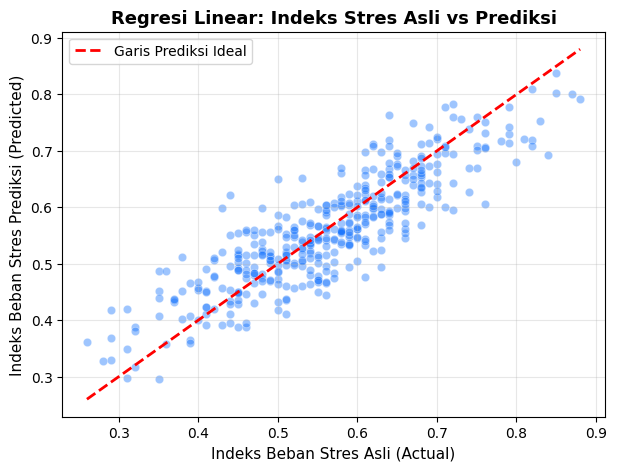

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Membersihkan data dari missing value (NaN) pada fitur dan target numerik
clean_reg_df = df.dropna(subset=features + ['indeks_beban_stres_kumulatif'])

# Target numerik untuk Regresi Linear
X = clean_reg_df[features]
y_reg = clean_reg_df['indeks_beban_stres_kumulatif']

# Split data 80% training, 20% testing
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# Melatih model Regresi Linear
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r)
y_pred_r = reg_model.predict(X_test_r)

# Evaluasi performa Regresi Linear
r2 = r2_score(y_test_r, y_pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print(f"=== HASIL EVALUASI REGRESI LINEAR ===")
print(f"R-Squared (R²) : {r2:.4f} (Model mampu menjelaskan {r2*100:.2f}% variasi tingkat stres)")
print(f"RMSE           : {rmse:.4f} (Rata-rata kesalahan prediksi sangat kecil)")

# Visualisasi Scatter Plot: Nilai Asli vs Prediksi Model
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.4, color='#0d6efd')
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2, label='Garis Prediksi Ideal')
plt.title('Regresi Linear: Indeks Stres Asli vs Prediksi', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Beban Stres Asli (Actual)', fontsize=11)
plt.ylabel('Indeks Beban Stres Prediksi (Predicted)', fontsize=11)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Analisis Tambahan: Heatmap Korelasi & Pengaruh Faktor

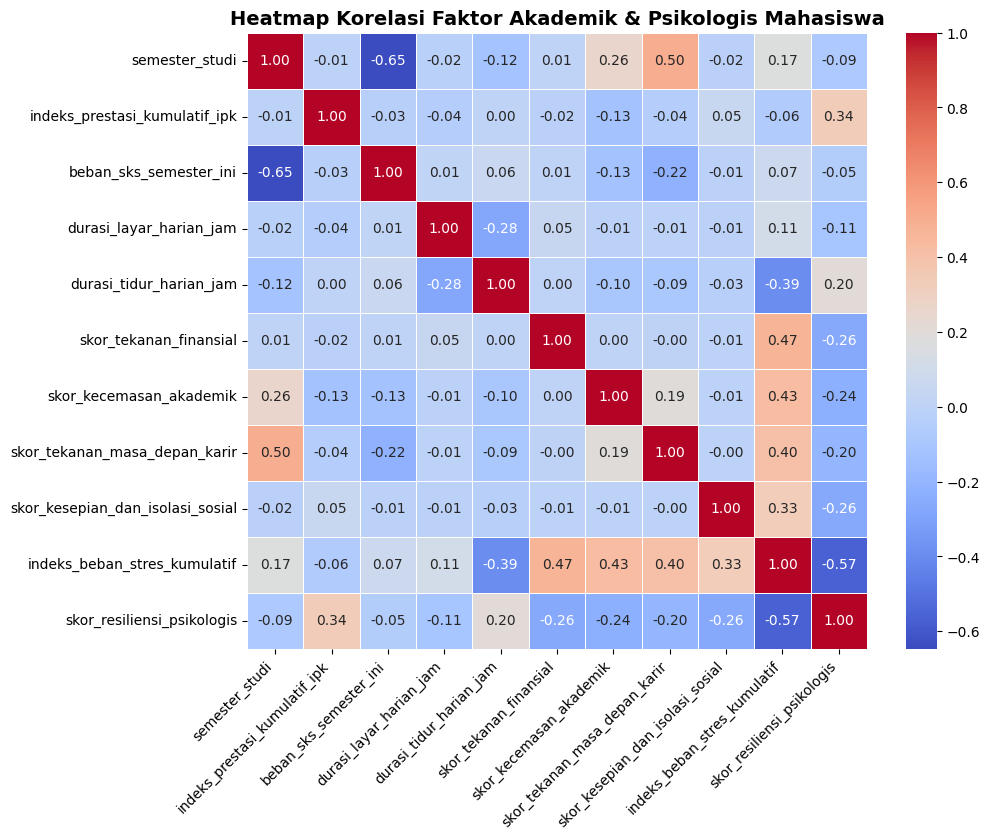

In [ ]:
# Menggabungkan fitur dan target numerik untuk melihat korelasinya
kolom_analisis = features + ['indeks_beban_stres_kumulatif', 'skor_resiliensi_psikologis']
korelasi = df[kolom_analisis].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Heatmap Korelasi Faktor Akademik & Psikologis Mahasiswa', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
import pandas as pd
from scipy import stats

# Menggunakan path lengkap ke folder /content/ agar file dapat ditemukan oleh Colab
df = pd.read_csv('/content/indonesia_kesehatan_mental_gen_z_akademik_enriched_2026.csv')

# 2. Menentukan Variabel X (Kategori Kelompok) dan Y (Variabel Numerik yang diuji)
# X: Aktivitas Pekerjaan Sampingan (Membandingkan 2 kelompok: Tidak Bekerja vs Kerja Part-Time)
# Y: Indeks Beban Stres Kumulatif
kelompok_1 = df[df['aktivitas_pekerjaan_sampingan'] == 'Tidak Bekerja / Fokus Kuliah']['indeks_beban_stres_kumulatif']
kelompok_2 = df[df['aktivitas_pekerjaan_sampingan'] == 'Kerja Part-Time F&B / Ritel']['indeks_beban_stres_kumulatif']

# 3. Melakukan Uji-t (Independent Sample t-Test / Welch's t-test)
t_stat, p_value = stats.ttest_ind(kelompok_1, kelompok_2, equal_var=False)

# 4. Menampilkan Hasil Analisis
print("="*50)
print("HASIL ANALISIS UJI-T (T-TEST)")
print("="*50)
print(f"Jumlah sampel Kelompok 1 (Fokus Kuliah) : {len(kelompok_1)}")
print(f"Jumlah sampel Kelompok 2 (Part-Time)    : {len(kelompok_2)}")
print(f"Rata-rata Stres (Kelompok 1)            : {kelompok_1.mean():.4f}")
print(f"Rata-rata Stres (Kelompok 2)            : {kelompok_2.mean():.4f}")
print(f"Nilai t-statistic                       : {t_stat:.4f}")
print(f"Nilai p-value                           : {p_value:.4e}")
print("="*50)

if p_value < 0.05:
    print("Kesimpulan: Terdapat perbedaan rata-rata tingkat stres yang SIGNIFIKAN secara statistik antara mahasiswa yang fokus kuliah dan yang bekerja part-time.")
else:
    print("Kesimpulan: Tidak terdapat perbedaan rata-rata tingkat stres yang signifikan antara kedua kelompok tersebut.")

HASIL ANALISIS UJI-T (T-TEST)
Jumlah sampel Kelompok 1 (Fokus Kuliah) : 943
Jumlah sampel Kelompok 2 (Part-Time)    : 373
Rata-rata Stres (Kelompok 1)            : 0.5585
Rata-rata Stres (Kelompok 2)            : 0.5623
Nilai t-statistic                       : -0.5119
Nilai p-value                           : 6.0887e-01
Kesimpulan: Tidak terdapat perbedaan rata-rata tingkat stres yang signifikan antara kedua kelompok tersebut.
